# TP6. Géométrie du plan

Carnet de travail. L'énoncé complet, avec les corrigés, est sur le site :
https://cours.gclab.fr/outils-fondamentaux/tp6-geometrie-plan/

Exécutez une cellule avec Maj+Entrée. **Pensez à télécharger ce carnet avant de partir** : menu File, puis Download.


## Exercice 1.1 : la boîte à outils

Écrivez `vecteur(A, B)`, `produit_scalaire(u, v)`, `norme(u)` et `angle(u, v)`, ce
dernier en degrés.

**Résultat attendu :** `norme((3, 4))` vaut `5.0`, `produit_scalaire((1, 2), (3, 4))`
vaut `11`, `angle((1, 0), (1, 1))` vaut `45.0` à l'arrondi près, et
`angle((1, 0), (0, 1))` vaut `90.0`.


In [15]:
import math

def vecteur(A, B):
    """Vecteur allant du point A au point B."""
    return (B[0] - A[0], B[1] - A[1])

def produit_scalaire(u, v):
    """Produit scalaire usuel de deux vecteurs."""
    return u[0] * v[0] + u[1] * v[1]

def norme(u):
    """Norme euclidienne d'un vecteur."""
    return math.hypot(u[0], u[1])

def angle(u, v):
    """Angle géométrique (non orienté) entre deux vecteurs, en degrés."""
    norme_u = norme(u)
    norme_v = norme(v)
    if norme_u == 0 or norme_v == 0:
        return 0.0
    # On borne entre -1 et 1 pour éviter les erreurs d'arrondi
    cosinus = produit_scalaire(u, v) / (norme_u * norme_v)
    cosinus = max(-1.0, min(1.0, cosinus))
    return math.degrees(math.acos(cosinus))

print("Norme :", norme((3, 4)))
print("Scalaire :", produit_scalaire((1, 2), (3, 4)))
print("Angle 45° :", round(angle((1, 0), (1, 1)), 2))
print("Angle 90° :", round(angle((1, 0), (0, 1)), 2))


Norme : 5.0
Scalaire : 11
Angle 45° : 45.0
Angle 90° : 90.0


## Exercice 1.2 : la distance d'un point à une droite

La distance du point $P$ à la droite $(AB)$ vaut
$\dfrac{|\vec{AB} \times \vec{AP}|}{\|\vec{AB}\|}$, où $\times$ désigne le
**déterminant** $u_x v_y - u_y v_x$, que l'étape suivante interprète. Écrivez
`determinant(u, v)` puis `distance_point_droite(P, A, B)`.

**Résultat attendu :** la distance de l'origine à la droite passant par $(0, 1)$ et
$(1, 0)$ vaut $\sqrt{2}/2 \approx 0{,}7071$, et celle de $(3, 4)$ à l'axe des
abscisses vaut `4.0`.


In [14]:
def determinant(u, v):
    """Déterminant de deux vecteurs dans le plan (x1*y2 - y1*x2)."""
    return u[0] * v[1] - u[1] * v[0]

def distance_point_droite(P, A, B):
    """Distance de P à la droite (AB)."""
    u = vecteur(A, B)
    v = vecteur(A, P)
    norme_u = norme(u)
    if norme_u == 0:
        raise ValueError("Les points A et B doivent être distincts.")
    return abs(determinant(u, v)) / norme_u

print("Distance à y=x :", distance_point_droite((0, 0), (1, 1), (2, 2))) # Origine sur la droite = 0.0
print("Distance à axe X :", distance_point_droite((0, 4), (0, 0), (1, 0))) # Hauteur de 4


Distance à y=x : 0.0
Distance à axe X : 4.0


## Exercice 2.1 : à gauche ou à droite ?

Écrivez `orientation(A, B, C)` qui renvoie `1` si le trajet $A \to B \to C$ tourne
à gauche, `-1` s'il tourne à droite, `0` si les trois points sont alignés.

**Résultat attendu :** `orientation((0, 0), (1, 0), (1, 1))` vaut `1`,
`orientation((0, 0), (1, 0), (1, -1))` vaut `-1`, et
`orientation((0, 0), (1, 1), (2, 2))` vaut `0`.


In [13]:
def orientation(A, B, C):
    """
    Renvoie :
      1 si le trajet A -> B -> C tourne à gauche (sens trigonométrique).
     -1 s'il tourne à droite (sens horaire).
      0 si A, B, C sont alignés.
    """
    det = determinant(vecteur(A, B), vecteur(B, C))
    # On utilise une tolérance pour les erreurs d'arrondi
    if det > 1e-12:
        return 1
    elif det < -1e-12:
        return -1
    else:
        return 0

print(orientation((0, 0), (1, 0), (1, 1)))   # 1 (gauche)
print(orientation((0, 0), (1, 0), (1, -1)))  # -1 (droite)
print(orientation((0, 0), (1, 1), (2, 2)))   # 0 (alignés)


1
-1
0


## Exercice 2.2 : l'aire d'un polygone

Un polygone est une liste de sommets dans l'ordre. Son aire vaut la moitié de la
valeur absolue de la somme des déterminants $x_i y_{i+1} - x_{i+1} y_i$ sur les
côtés consécutifs, le dernier sommet étant relié au premier : c'est la **formule du
lacet**. Écrivez `aire(polygone)`.

**Résultat attendu :** le carré unité a une aire de `1.0`, le triangle
$(0,0), (4,0), (0,3)$ une aire de `6.0`, et la maison du TP4,
`[(0, 0), (2, 0), (2, 1.5), (1, 2.5), (0, 1.5)]`, une aire de `4.0`.


In [12]:
def aire(polygone):
    """Aire d'un polygone (liste de points) par la formule du lacet."""
    if len(polygone) < 3:
        return 0.0
    somme = 0.0
    n = len(polygone)
    for i in range(n):
        somme += determinant(polygone[i], polygone[(i + 1) % n])
    return abs(somme) / 2.0

carre = [(0, 0), (1, 0), (1, 1), (0, 1)]
triangle = [(0, 0), (4, 0), (0, 3)]
maison = [(0, 0), (2, 0), (2, 1.5), (1, 2.5), (0, 1.5)]

print("Aire carré :", aire(carre))       # 1.0
print("Aire triangle :", aire(triangle)) # 6.0
print("Aire maison :", aire(maison))     # 4.0

Aire carré : 1.0
Aire triangle : 6.0
Aire maison : 4.0


## Exercice 3.1 : le test de croisement

Écrivez `se_coupent(A, B, C, D)` avec quatre appels à `orientation`. Ne traitez pas les
cas où trois points sont alignés : renvoyez `False`, et notez-le dans la docstring.

**Résultat attendu :** les diagonales du carré unité se coupent ; les segments
$[(0,0), (1, 0)]$ et $[(0, 1), (1, 1)]$, parallèles, ne se coupent pas ;
$[(0,0), (1,1)]$ et $[(2,2), (3,3)]$, alignés mais disjoints, non plus.


In [16]:
# On redéfinit les fonctions nécessaires pour être sûr qu'elles sont en mémoire
def vecteur(A, B):
    return (B[0] - A[0], B[1] - A[1])

def determinant(u, v):
    return u[0] * v[1] - u[1] * v[0]

def orientation(A, B, C):
    det = determinant(vecteur(A, B), vecteur(B, C))
    if det > 1e-12: return 1
    elif det < -1e-12: return -1
    else: return 0

# La fonction de l'exercice 3.1
def se_coupent(A, B, C, D):
    """
    Vrai si le segment ouvert [AB] croise le segment ouvert [CD].
    Renvoie False si trois des points sont alignés.
    """
    o1 = orientation(A, B, C)
    o2 = orientation(A, B, D)
    o3 = orientation(C, D, A)
    o4 = orientation(C, D, B)
    
    if o1 == 0 or o2 == 0 or o3 == 0 or o4 == 0:
        return False
        
    return o1 != o2 and o3 != o4

print("Diagonales carré :", se_coupent((0, 0), (1, 1), (1, 0), (0, 1))) 
print("Parallèles :", se_coupent((0, 0), (1, 0), (0, 1), (1, 1)))       
print("Alignés disjoints :", se_coupent((0, 0), (1, 0), (2, 0), (3, 0)))

Diagonales carré : True
Parallèles : False
Alignés disjoints : False




Quand les segments se coupent, on veut souvent le point. En écrivant
$A + t\,\vec{AB} = C + u\,\vec{CD}$, on obtient un système de deux équations à deux
inconnues $t$ et $u$, que les déterminants résolvent directement :
$t = \dfrac{\vec{AC} \times \vec{CD}}{\vec{AB} \times \vec{CD}}$ et
$u = \dfrac{\vec{AC} \times \vec{AB}}{\vec{AB} \times \vec{CD}}$. Écrivez
`intersection(A, B, C, D)` qui renvoie le point, ou `None` si les segments ne se
coupent pas.

**Résultat attendu :** les diagonales du carré de côté 2 se coupent en `(1.0, 1.0)`.


In [17]:
def intersection(A, B, C, D):
    """Point d'intersection de [AB] et [CD], ou None s'ils ne se coupent pas."""
    # se_coupent doit avoir été exécuté dans la cellule précédente
    if not se_coupent(A, B, C, D):
        return None
        
    u = vecteur(A, B)
    v = vecteur(C, D)
    det = determinant(u, v) 
    
    w = vecteur(C, A)
    t = determinant(v, w) / det
    
    return (A[0] + t * u[0], A[1] + t * u[1])

print("Intersection diagonales :", intersection((0, 0), (2, 2), (2, 0), (0, 2)))


Intersection diagonales : (1.0, 1.0)


## Exercice 4.1 : le lancer de rayon

Écrivez `dedans(P, polygone)`. Pour chaque côté $[S_i S_{i+1}]$, le rayon le
traverse si les deux ordonnées encadrent celle de $P$ et si l'abscisse du point de
croisement, obtenue par interpolation, est à droite de $P$.

**Résultat attendu :** dans la maison, `(1, 1)` et `(1, 2.4)` sont dedans, `(3, 1)`
et `(0.2, 2.2)` sont dehors.


In [7]:
def dedans(P, polygone):
    """Vrai si le point P est strictement à l'intérieur du polygone."""
    x, y = P
    n = len(polygone)
    croisements = 0
    
    for i in range(n):
        A = polygone[i]
        B = polygone[(i + 1) % n]
        
        
        y_min = min(A[1], B[1])
        y_max = max(A[1], B[1])
        
        if y_min < y <= y_max:
            
            if A[1] != B[1]:
                t = (y - A[1]) / (B[1] - A[1])
                x_inter = A[0] + t * (B[0] - A[0])
                if x_inter > x: 
                    croisements += 1
                    
    return croisements % 2 == 1

maison = [(0, 0), (2, 0), (2, 1.5), (1, 2.5), (0, 1.5)]
print("Dedans (1, 1) :", dedans((1, 1), maison))         # True
print("Dedans (1, 2.4) :", dedans((1, 2.4), maison))     # True
print("Dehors (3, 1) :", dedans((3, 1), maison))         # False
print("Dehors (0.2, 2.2) :", dedans((0.2, 2.2), maison)) # False


Dedans (1, 1) : True
Dedans (1, 2.4) : True
Dehors (3, 1) : False
Dehors (0.2, 2.2) : False


## Exercice 4.2 : l'aire par le hasard

On peut estimer une aire sans formule : tirer des points au hasard dans un rectangle
qui contient la figure, compter ceux qui tombent dedans, et multiplier la proportion
par l'aire du rectangle. C'est la **méthode de Monte-Carlo**. Estimez ainsi l'aire de
la maison avec 200 000 points tirés dans le rectangle $[0, 2] \times [0, 2{,}5]$.

**Résultat attendu :** une valeur proche de `4.0`, à quelques centièmes près, et qui
change à chaque exécution si vous ne fixez pas la graine.


In [6]:
import random

def aire_monte_carlo(polygone, x_min, x_max, y_min, y_max, n_points):
    """Estime l'aire par la méthode de Monte-Carlo."""
    points_dedans = 0
    for _ in range(n_points):
        px = random.uniform(x_min, x_max)
        py = random.uniform(y_min, y_max)
        if dedans((px, py), polygone):
            points_dedans += 1
            
    aire_rectangle = (x_max - x_min) * (y_max - y_min)
    proportion = points_dedans / n_points
    return proportion * aire_rectangle

maison = [(0, 0), (2, 0), (2, 1.5), (1, 2.5), (0, 1.5)]

estimation = aire_monte_carlo(maison, 0.0, 2.0, 0.0, 2.5, 200_000)
print(f"Estimation Monte-Carlo : {estimation:.2f}") # Proche de 4.0


Estimation Monte-Carlo : 4.00


## Exercice 5.1 : un polygone qui n'est pas convexe

Construisez un polygone en forme de L ou d'étoile, non convexe, et vérifiez sur un
tracé que `dedans` et `aire` donnent des résultats corrects, y compris dans le creux.


Aire L théorique : 5.0 | Calculée : 5.0
Point (2, 2) dedans ? : False
Point (0.5, 0.5) dedans ? : True


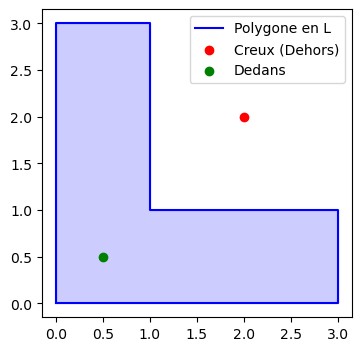

In [18]:
import matplotlib.pyplot as plt


forme_L = [(0, 0), (3, 0), (3, 1), (1, 1), (1, 3), (0, 3)]

print("Aire L théorique : 5.0 | Calculée :", aire(forme_L))


xs = [p[0] for p in forme_L] + [forme_L[0][0]]
ys = [p[1] for p in forme_L] + [forme_L[0][1]]

plt.figure(figsize=(4, 4))
plt.plot(xs, ys, label="Polygone en L", color="blue")
plt.fill(xs, ys, alpha=0.2, color="blue")


creux = (2, 2)
plt.scatter(*creux, color="red", label="Creux (Dehors)")
print(f"Point {creux} dedans ? :", dedans(creux, forme_L)) # False


in_L = (0.5, 0.5)
plt.scatter(*in_L, color="green", label="Dedans")
print(f"Point {in_L} dedans ? :", dedans(in_L, forme_L))   # True

plt.legend()
plt.show()

## Exercice 6.1 : le polygone le plus proche

On dispose de plusieurs polygones, par exemple les zones d'une carte, et d'un point
cliqué. Écrivez `zone_de(P, zones)` qui renvoie l'indice de la zone contenant `P`, ou
`None`. Testez avec la maison et le carré `[(3, 0), (4, 0), (4, 1), (3, 1)]`.

**Résultat attendu :** `(1, 1)` est dans la zone `0`, `(3.5, 0.5)` dans la zone `1`,
`(2.5, 0.5)` dans aucune.


In [5]:
def dedans(P, polygone):
    """Vrai si le point P est strictement à l'intérieur du polygone."""
    x, y = P
    n = len(polygone)
    croisements = 0
    
    for i in range(n):
        A = polygone[i]
        B = polygone[(i + 1) % n]
        
        
        y_min = min(A[1], B[1])
        y_max = max(A[1], B[1])
        
        if y_min < y <= y_max:
            
            if A[1] != B[1]:
                t = (y - A[1]) / (B[1] - A[1])
                x_inter = A[0] + t * (B[0] - A[0])
                if x_inter > x: 
                    croisements += 1
                    
    return croisements % 2 == 1

def zone_de(P, zones):
    """Renvoie l'indice de la première zone contenant P, ou None."""
    for i, polygone in enumerate(zones):
        if dedans(P, polygone):
            return i
    return None

maison = [(0, 0), (2, 0), (2, 1.5), (1, 2.5), (0, 1.5)]
carre = [(3, 0), (4, 0), (4, 1), (3, 1)]
zones_carte = [maison, carre]

print("(1, 1) zone :", zone_de((1, 1), zones_carte))         # 0
print("(3.5, 0.5) zone :", zone_de((3.5, 0.5), zones_carte)) # 1
print("(2.5, 0.5) zone :", zone_de((2.5, 0.5), zones_carte)) # None


(1, 1) zone : 0
(3.5, 0.5) zone : 1
(2.5, 0.5) zone : None
